In [ ]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Nadine1105")  

driver = GraphDatabase.driver(URI, auth=AUTH)

driver.verify_connectivity()

print("Koneksi ke Neo4j berhasil!")

Koneksi ke Neo4j berhasil!


In [7]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )

In [8]:
def print_friends(driver, name):
    records, summary, keys = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) "
        "WHERE a.name = $name "
        "RETURN friend.name AS friend_name "
        "ORDER BY friend_name",
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend_name"])

In [9]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Teman Arthur:")
    print_friends(driver, "Arthur")

Teman Arthur:
Guinevere
Lancelot
Merlin


### Soal UTS

In [ ]:
import os
import pandas as pd
from getpass import getpass
from tqdm import tqdm
from neo4j import GraphDatabase

uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "..."

driver = GraphDatabase.driver(uri,auth=(user, password))

driver.verify_connectivity()

print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


In [23]:
csv_file_path = os.path.join("data", "events.csv")

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(
        f"File '{csv_file_path}' tidak ditemukan!"
    )

print("File events.csv ditemukan!")

File events.csv ditemukan!


In [24]:
events = pd.read_csv(csv_file_path)

print("Ukuran dataset:", events.shape)
print("\nNama kolom:")
print(events.columns.tolist())

display(events.head())

total_rows = len(events)

print("\nJumlah total data:", total_rows)

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Jumlah total data: 2756101


In [19]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """).consume()

    print("Constraint berhasil disiapkan!")

In [25]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """

    tx.run(cypher_query, batch=batch)

In [26]:
batch_size = 10000

with driver.session(database="neo4j") as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")

    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    total_rows = len(events)
    total_chunks = (total_rows + batch_size - 1) // batch_size

    print("Memulai proses impor data ke Neo4j...")

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor Batch Data"
    ):
        chunk["transactionid"] = (
            chunk["transactionid"]
            .fillna("")
            .astype(str)
        )

        records = chunk.to_dict(orient="records")

        session.execute_write(import_batch, records)

driver.close()

print("Proses impor berhasil.")

Constraint berhasil disiapkan!
Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [03:00<00:00,  1.53it/s]

Proses impor berhasil.


In [27]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (v:Visitor)
        WITH count(v) AS total_visitor

        MATCH (i:Item)
        WITH total_visitor, count(i) AS total_item

        OPTIONAL MATCH ()-[r]->()

        RETURN
            total_visitor,
            total_item,
            count(r) AS total_relationship
    """)

    hasil = dict(result.single())

    print("Hasil impor:")
    print("Total Visitor:", hasil["total_visitor"])
    print("Total Item:", hasil["total_item"])
    print("Total Relationship:", hasil["total_relationship"])

C:\Users\User\AppData\Local\Temp\ipykernel_27764\3633400751.py:1: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


Hasil impor:
Total Visitor: 1407580
Total Item: 235061
Total Relationship: 2756106


In [28]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH ()-[r]->()
        RETURN
            type(r) AS jenis_relasi,
            count(r) AS jumlah
        ORDER BY jumlah DESC
    """)

    df_relasi = pd.DataFrame([
        dict(record) for record in result
    ])

display(df_relasi)

driver.close()

print("Koneksi Neo4j ditutup.")

C:\Users\User\AppData\Local\Temp\ipykernel_27764\886256415.py:1: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


,jenis_relasi,jumlah
0,VIEWED,2664312
1,ADDED_TO_CART,69332
2,BOUGHT,22457
3,SIMILAR_TO,5


Koneksi Neo4j ditutup.


In [34]:
events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    errors="coerce"
)

print("Tanggal paling awal:", events["datetime"].min())
print("Tanggal paling akhir:", events["datetime"].max())

Tanggal paling awal: 2015-05-03 03:00:04.384000
Tanggal paling akhir: 2015-09-18 02:59:47.788000


In [ ]:
kolom = ["visitorid", "itemid", "timestamp", "event"]

unik_csv = (
    events[kolom]
    .drop_duplicates()
    .groupby("event")
    .size()
    .rename("kombinasi_unik_csv")
    .reset_index()
)

display(unik_csv)

,event,kombinasi_unik_csv
0,addtocart,68966
1,transaction,22457
2,view,2664218


#### Soal no. 1 Tentukan 2 periode waktu sebagai filter dari data interaksi.

In [3]:
df = pd.read_csv("data/events.csv", usecols=["timestamp"])
df["tanggal"] = pd.to_datetime(df["timestamp"],unit="ms", errors="coerce")

jumlah_harian = (df.groupby(df["tanggal"].dt.date).size().rename("jumlah_interaksi"))

kumulatif = jumlah_harian.cumsum()

target_training = len(df) * 0.60

tanggal_batas = ((kumulatif - target_training).abs().idxmin())

jumlah_training = kumulatif.loc[tanggal_batas]
jumlah_testing = len(df) - jumlah_training

print("Total interaksi:", len(df))
print("Target training 60%:", round(target_training))
print("Tanggal batas P1:", tanggal_batas)
print("Jumlah interaksi P1:", jumlah_training)
print("Jumlah interaksi P2:", jumlah_testing)
print("Persentase P1:", round(jumlah_training / len(df) * 100, 2), "%")
print("Persentase P2:", round(jumlah_testing / len(df) * 100, 2), "%")

Total interaksi: 2756101
Target training 60%: 1653661
Tanggal batas P1: 2015-07-21
Jumlah interaksi P1: 1658879
Jumlah interaksi P2: 1097222
Persentase P1: 60.19 %
Persentase P2: 39.81 %


In [5]:
periode = {
    "P1 mulai": "2015-05-03",
    "P1 selesai": "2015-07-21",
    "P2 mulai": "2015-07-22",
    "P2 selesai": "2015-09-18"
}

for nama, tanggal in periode.items():
    waktu = pd.Timestamp(tanggal, tz="UTC")

    unix_detik = int(waktu.timestamp())

    print(f"{nama} ({tanggal})")
    print(f"  UNIX detik      : {unix_detik}")

P1 mulai (2015-05-03)
  UNIX detik      : 1430611200
P1 selesai (2015-07-21)
  UNIX detik      : 1437436800
P2 mulai (2015-07-22)
  UNIX detik      : 1437523200
P2 selesai (2015-09-18)
  UNIX detik      : 1442534400


#### Soal No.2 Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv

In [31]:
events = pd.read_csv("data/events.csv")

events["datetime"] = pd.to_datetime(events["timestamp"], unit="ms", errors="coerce")

batas = pd.Timestamp("2015-07-22")

data_p1 = events[events["datetime"] < batas].copy()
data_p2 = events[events["datetime"] >= batas].copy()

data_p1.drop(columns=["datetime"]).to_csv(
    "data/events_training.csv", index=False
)
data_p2.drop(columns=["datetime"]).to_csv(
    "data/events_testing.csv", index=False
)

total = len(events)

print("Total interaksi:", total)
print("\nP1 - Training")
print("Jumlah:", len(data_p1))
print("Persentase:", round(len(data_p1) / total * 100, 2), "%")

print("\nP2 - Testing")
print("Jumlah:", len(data_p2))
print("Persentase:", round(len(data_p2) / total * 100, 2), "%")

print("\nTotal P1 + P2:", len(data_p1) + len(data_p2))
print("\nCSV P1 dan P2 berhasil disimpan.")

Total interaksi: 2756101

P1 - Training
Jumlah: 1658879
Persentase: 60.19 %

P2 - Testing
Jumlah: 1097222
Persentase: 39.81 %

Total P1 + P2: 2756101

CSV P1 dan P2 berhasil disimpan.


#### No.3 Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [ ]:
uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "..."

driver = GraphDatabase.driver(uri,auth=(user, password))

driver.verify_connectivity()

print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


In [28]:
batas = pd.Timestamp("2015-07-22", tz="UTC")
batas_timestamp = int(batas.timestamp() * 1000)

print(batas_timestamp)

1437523200000


In [30]:
batas_timestamp = 1437523200000

query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp < $batas
RETURN
    'P1 - Training' AS periode,
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(r) AS total_relasi,
    count(CASE WHEN type(r) = 'VIEWED' THEN 1 END) AS VIEWED,
    count(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 END) AS ADDED_TO_CART,
    count(CASE WHEN type(r) = 'BOUGHT' THEN 1 END) AS BOUGHT

UNION ALL

MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $batas
RETURN
    'P2 - Testing' AS periode,
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(r) AS total_relasi,
    count(CASE WHEN type(r) = 'VIEWED' THEN 1 END) AS VIEWED,
    count(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 END) AS ADDED_TO_CART,
    count(CASE WHEN type(r) = 'BOUGHT' THEN 1 END) AS BOUGHT
"""

with driver.session(database="neo4j") as session:
    hasil = session.run(
        query,
        batas=batas_timestamp
    ).data()

df_komposisi = pd.DataFrame(hasil)
display(df_komposisi)

,periode,jumlah_visitor,jumlah_item,total_relasi,VIEWED,ADDED_TO_CART,BOUGHT
0,P1 - Training,842565,189172,1658879,1604683,40798,13398
1,P2 - Testing,598095,158967,1097222,1059629,28534,9059


Graph yang digunakan memiliki dua jenis simpul, yaitu Visitor dan Item. Visitor merupakan pengunjung yang melakukan interaksi, sedangkan Item merupakan produk yang berinteraksi dengan pengunjung. Kedua jenis simpul tersebut dihubungkan oleh tiga jenis relasi, yaitu VIEWED untuk aktivitas melihat produk, ADDED_TO_CART untuk aktivitas menambahkan produk ke keranjang, dan BOUGHT untuk aktivitas pembelian produk.

Berdasarkan hasil query, subgraph P1 (Training) memiliki 842.565 Visitor dan 189.172 Item, dengan total 1.658.879 relasi. Relasi tersebut terdiri dari 1.604.683 VIEWED, 40.798 ADDED_TO_CART, dan 13.398 BOUGHT.

Sementara itu, subgraph P2 (Testing) memiliki 598.095 Visitor dan 158.967 Item, dengan total 1.097.222 relasi. Relasi tersebut terdiri dari 1.059.629 VIEWED, 28.534 ADDED_TO_CART, dan 9.059 BOUGHT.

Dari hasil tersebut, terlihat bahwa relasi VIEWED memiliki jumlah paling banyak pada kedua periode, sedangkan relasi BOUGHT memiliki jumlah paling sedikit. Hal ini menunjukkan bahwa interaksi melihat produk lebih sering terjadi dibandingkan interaksi menambahkan produk ke keranjang maupun membeli produk.

Query yang digunakan ditulis menggunakan Cypher untuk mengambil dan mengolah data pada graph Neo4j. Perintah MATCH digunakan untuk mencari pola simpul Visitor, relasi, dan Item. Perintah WHERE digunakan untuk memisahkan relasi berdasarkan timestamp sehingga data dapat dikelompokkan ke dalam P1 dan P2. Selanjutnya, count(DISTINCT v) dan count(DISTINCT i) digunakan untuk menghitung jumlah Visitor dan Item yang unik pada setiap periode, sedangkan count(r) digunakan untuk menghitung total relasi. Perintah CASE WHEN digunakan untuk menghitung masing-masing jenis relasi berdasarkan tipenya. Terakhir, UNION ALL digunakan untuk menggabungkan hasil P1 dan P2 ke dalam satu tabel. Hasil query kemudian diambil menggunakan Neo4j Python Driver melalui session.run(),

#### Soal no.4 Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape,plot networkx, dst.)!

In [35]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from matplotlib.lines import Line2D

In [ ]:
events_training = pd.read_csv("data/events_training.csv")

data_user = (
    events_training.groupby("visitorid")["itemid"]
    .apply(lambda x: " ".join(x.astype(str)))
)

vectorizer = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

user_item_matrix = vectorizer.fit_transform(data_user)

density = (
    user_item_matrix.nnz
    / (user_item_matrix.shape[0] * user_item_matrix.shape[1])
) * 100

print("Karakteristik VSM User-Item")
print("Dimensi matriks:", user_item_matrix.ndim)
print("Shape matriks:", user_item_matrix.shape)
print("Jumlah user:", user_item_matrix.shape[0])
print("Jumlah item:", user_item_matrix.shape[1])
print("Jumlah nilai nonzero:", user_item_matrix.nnz)
print("Kepadatan matriks:", round(density, 6), "%")

Karakteristik VSM User-Item
Dimensi matriks: 2
Shape matriks: (842565, 189172)
Jumlah user: 842565
Jumlah item: 189172
Jumlah nilai nonzero: 1284423
Kepadatan matriks: 0.000806 %


In [ ]:
user_aktif = (
    events_training.groupby("visitorid")["itemid"]
    .count()
    .nlargest(100)
    .index
)

user_index = pd.Series(
    range(len(data_user)),
    index=data_user.index
)

indeks_sampel = user_index.loc[user_aktif].values
matriks_sampel = user_item_matrix[indeks_sampel]

print("Jumlah user yang divisualisasikan:", matriks_sampel.shape[0])

Jumlah user yang divisualisasikan: 100


In [ ]:
similarity = cosine_similarity(matriks_sampel)

print("Shape matriks similarity:", similarity.shape)

Shape matriks similarity: (100, 100)


In [ ]:
G_user = nx.Graph()

G_user.add_nodes_from(range(len(user_aktif)))

k = 3

for i in range(len(user_aktif)):
    urutan = np.argsort(similarity[i])[::-1]

    tetangga = [
        j for j in urutan
        if j != i and similarity[i, j] > 0
    ][:k]

    for j in tetangga:
        G_user.add_edge(
            i,
            j,
            weight=float(similarity[i, j])
        )

derajat = dict(G_user.degree())

print("Karakteristik Graf User-User")
print("Jumlah node:", G_user.number_of_nodes())
print("Jumlah edge:", G_user.number_of_edges())
print("Jumlah komponen terhubung:", nx.number_connected_components(G_user))
print("Rata-rata derajat:", round(np.mean(list(derajat.values())), 2))

Karakteristik Graf User-User
Jumlah node: 100
Jumlah edge: 251
Jumlah komponen terhubung: 1
Rata-rata derajat: 5.02


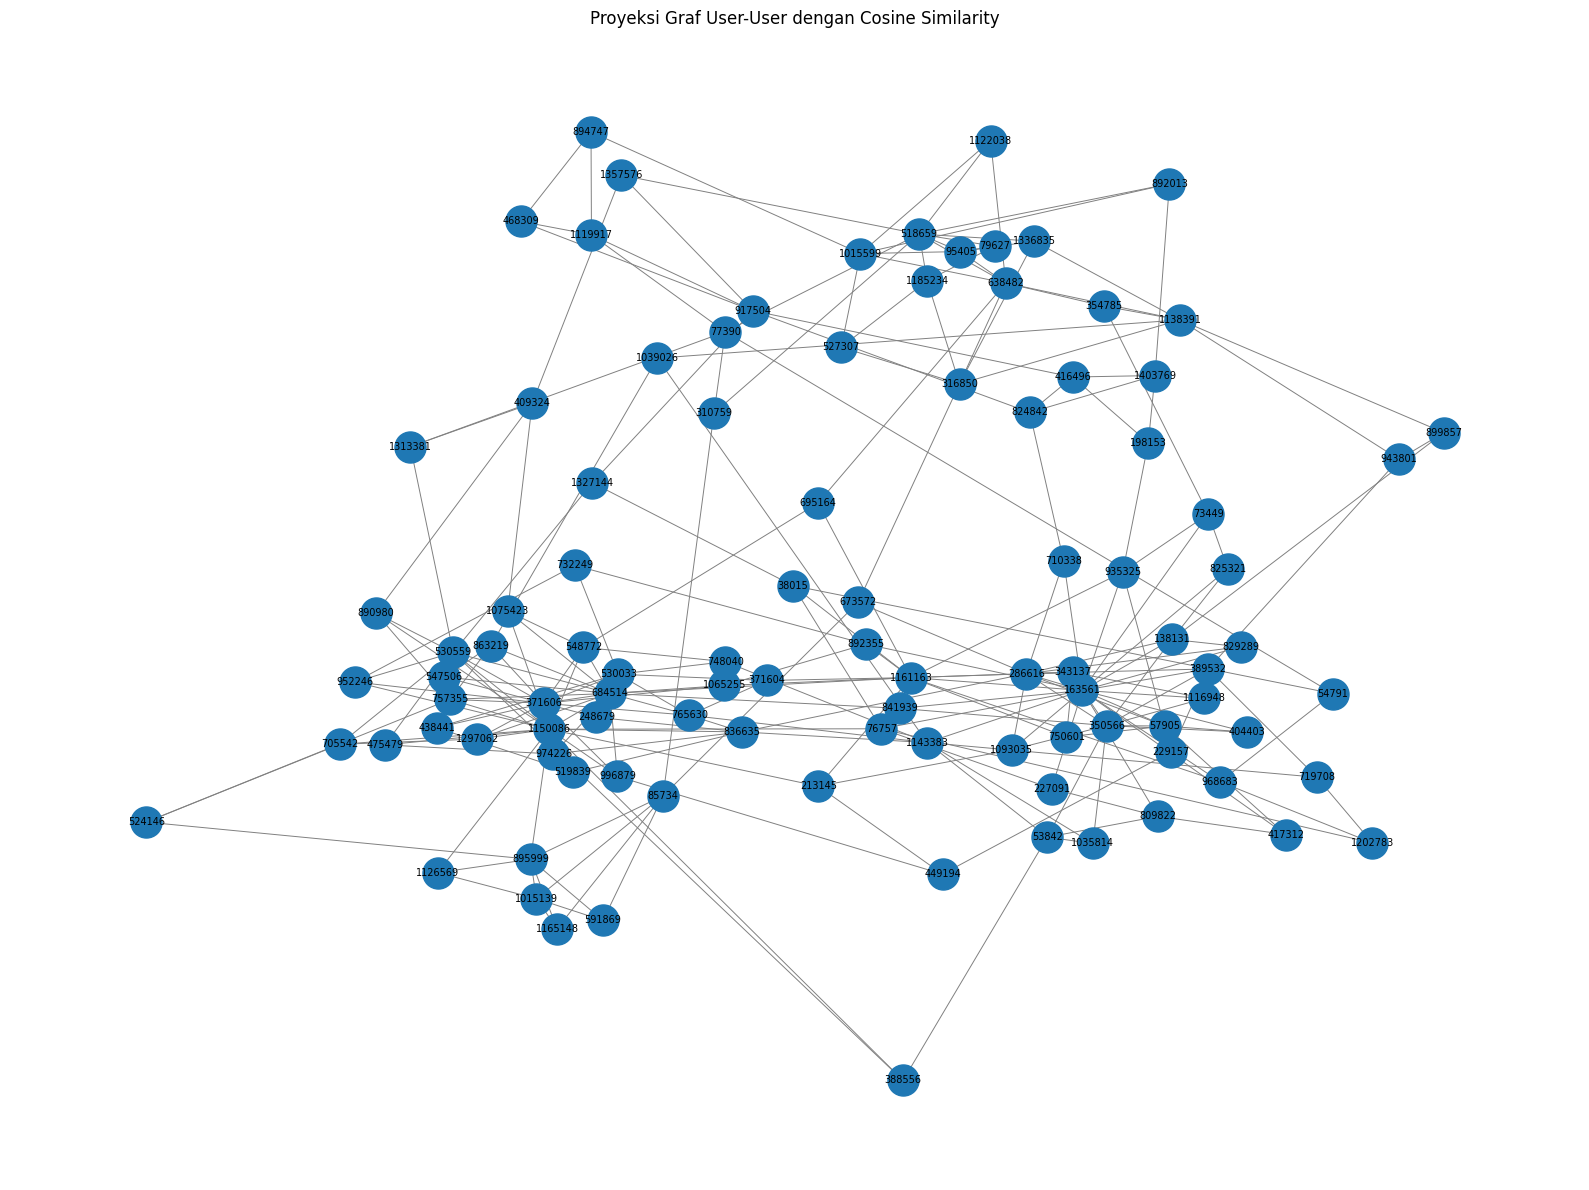

In [ ]:
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G_user, seed=42)

label_user = {
    i: str(user_aktif[i])
    for i in range(len(user_aktif))
}

nx.draw_networkx(
    G_user,
    pos,
    labels=label_user,
    with_labels=True,
    node_size=500,
    font_size=7,
    font_color="black",
    edge_color="gray",
    width=0.7
)

plt.title("Proyeksi Graf User-User dengan Cosine Similarity")
plt.axis("off")
plt.tight_layout()
plt.show()

Pada tahap ini dilakukan Vector Space Modelling (VSM) terhadap simpul Visitor yang diasumsikan sebagai User menggunakan data training. Setiap user direpresentasikan berdasarkan item yang pernah diinteraksikan. Data dikelompokkan berdasarkan visitorid, kemudian diubah menjadi matriks VSM User-Item menggunakan CountVectorizer.

Berdasarkan hasil yang diperoleh, matriks VSM memiliki shape (842.565, 189.172), yang berarti terdiri dari 842.565 user sebagai baris dan 189.172 item sebagai kolom. Matriks memiliki 1.284.423 nilai nonzero dengan kepadatan sebesar 0,000806%. Kepadatan yang sangat rendah menunjukkan bahwa sebagian besar pasangan user-item tidak memiliki interaksi, sehingga matriks bersifat sparse. Nilai pada matriks menunjukkan frekuensi interaksi user terhadap item, sehingga dapat lebih dari satu jika user berinteraksi dengan item yang sama beberapa kali.

Selanjutnya, VSM digunakan untuk menghitung kemiripan antar-user menggunakan Cosine Similarity. Karena jumlah user sangat besar, perhitungan dan visualisasi graf dilakukan pada 100 user paling aktif. Hasil perhitungan menghasilkan matriks similarity dengan shape (100, 100), yang menunjukkan tingkat kemiripan antar-user dalam sampel tersebut.

Hasil similarity kemudian divisualisasikan menggunakan NetworkX dalam bentuk graf User-User. Setiap node mewakili satu user, sedangkan edge menunjukkan hubungan antara user yang memiliki nilai similarity positif dan terpilih sebagai tetangga dengan similarity tertinggi. Graf yang terbentuk memiliki 100 node, 251 edge, 1 komponen terhubung, dan rata-rata derajat 5,02. Dengan demikian, VSM digunakan untuk merepresentasikan interaksi user terhadap item, sedangkan Cosine Similarity dan NetworkX membantu menunjukkan kemiripan serta hubungan antar-user berdasarkan pola interaksi mereka.

#### Soal no.5 Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [45]:
events_training = pd.read_csv("data/events_training.csv")

data_item = (
    events_training.groupby("itemid")["visitorid"]
    .apply(lambda x: " ".join(x.astype(str)))
)

vectorizer_item = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

item_user_matrix = vectorizer_item.fit_transform(data_item)
density = (
    item_user_matrix.nnz
    / (item_user_matrix.shape[0] * item_user_matrix.shape[1])
) * 100

print("Karakteristik VSM Item-User")
print("Dimensi matriks:", item_user_matrix.ndim)
print("Shape matriks:", item_user_matrix.shape)
print("Jumlah item:", item_user_matrix.shape[0])
print("Jumlah user:", item_user_matrix.shape[1])
print("Jumlah nilai nonzero:", item_user_matrix.nnz)
print("Kepadatan matriks:", round(density, 6), "%")


Karakteristik VSM Item-User
Dimensi matriks: 2
Shape matriks: (189172, 842565)
Jumlah item: 189172
Jumlah user: 842565
Jumlah nilai nonzero: 1284423
Kepadatan matriks: 0.000806 %


In [ ]:
item_aktif = (
    events_training.groupby("itemid")["visitorid"]
    .count()
    .nlargest(100)
    .index
)

item_index = pd.Series(
    range(len(data_item)),
    index=data_item.index
)

indeks_item = item_index.loc[item_aktif].values
matriks_item_sampel = item_user_matrix[indeks_item]

print("Jumlah item yang divisualisasikan:", matriks_item_sampel.shape[0])

Jumlah item yang divisualisasikan: 100


In [ ]:
similarity_item = cosine_similarity(matriks_item_sampel)

print("Shape matriks similarity:", similarity_item.shape)

Shape matriks similarity: (100, 100)


In [ ]:
G_item = nx.Graph()
G_item.add_nodes_from(range(len(item_aktif)))

k = 3

for i in range(len(item_aktif)):
    urutan = np.argsort(similarity_item[i])[::-1]

    tetangga = [
        j for j in urutan
        if j != i and similarity_item[i, j] > 0
    ][:k]

    for j in tetangga:
        G_item.add_edge(
            i,
            j,
            weight=float(similarity_item[i, j])
        )

derajat = dict(G_item.degree())

print("Karakteristik Graf Item-Item")
print("Jumlah node:", G_item.number_of_nodes())
print("Jumlah edge:", G_item.number_of_edges())
print("Jumlah komponen terhubung:", nx.number_connected_components(G_item))
print("Rata-rata derajat:",round(np.mean(list(derajat.values())), 2))

Karakteristik Graf Item-Item
Jumlah node: 100
Jumlah edge: 230
Jumlah komponen terhubung: 4
Rata-rata derajat: 4.6


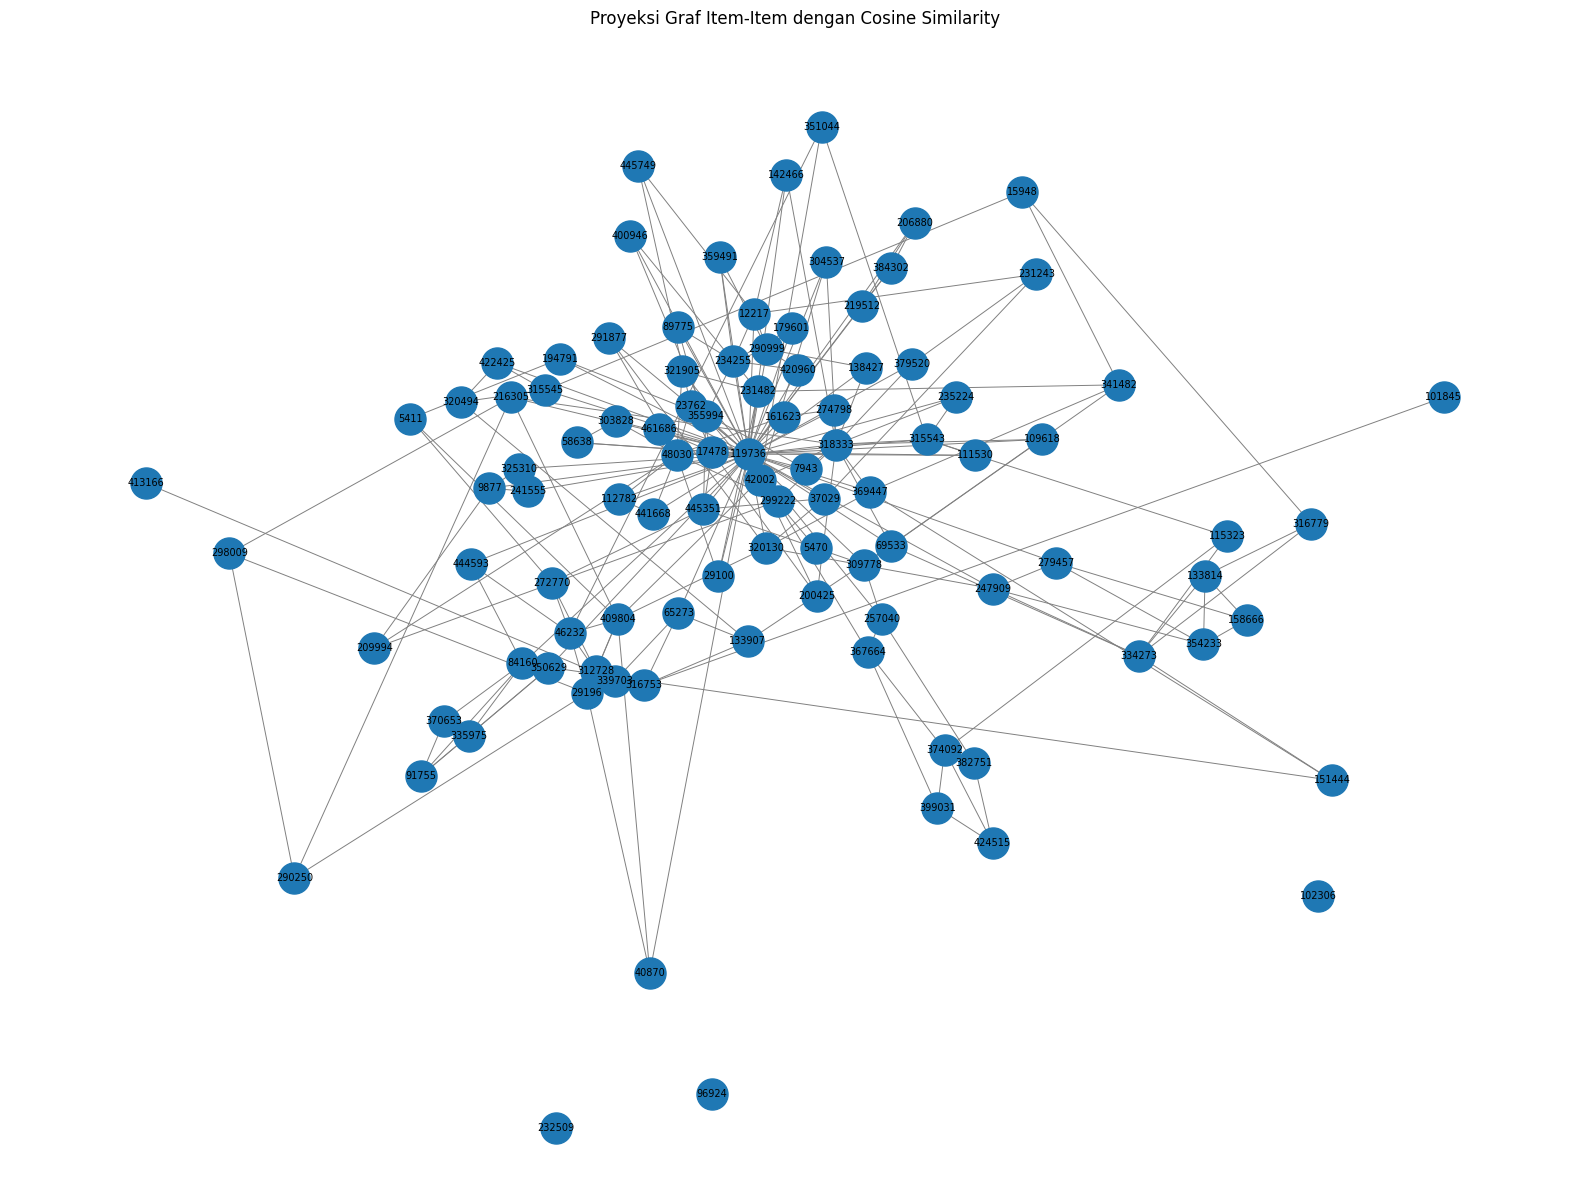

In [50]:
plt.figure(figsize=(16, 12))

pos_item = nx.spring_layout(G_item, seed=42)

label_item = {
    i: str(item_aktif[i])
    for i in range(len(item_aktif))
}

nx.draw_networkx(
    G_item,
    pos=pos_item,
    labels=label_item,
    with_labels=True,
    node_size=500,
    font_size=7,
    edge_color="gray",
    width=0.7
)

plt.title("Proyeksi Graf Item-Item dengan Cosine Similarity")
plt.axis("off")
plt.tight_layout()
plt.show()

Pada tahap ini dilakukan Vector Space Modelling (VSM) terhadap simpul Item menggunakan data training. Setiap item direpresentasikan berdasarkan user yang pernah berinteraksi dengannya. Data dikelompokkan berdasarkan itemid, kemudian diubah menjadi matriks VSM Item-User menggunakan CountVectorizer.

Berdasarkan hasil yang diperoleh, matriks VSM memiliki dimensi 2 dengan shape (189.172, 842.565), yang berarti terdiri dari 189.172 item sebagai baris dan 842.565 user sebagai kolom. Matriks memiliki 1.284.423 nilai nonzero dengan kepadatan sebesar 0,000806%. Kepadatan yang sangat rendah menunjukkan bahwa hanya sebagian kecil pasangan item-user yang memiliki interaksi, sehingga matriks bersifat *sparse*. Nilai pada matriks menunjukkan frekuensi interaksi item dengan user, sehingga nilainya dapat lebih dari satu apabila user yang sama berinteraksi dengan item tersebut beberapa kali.

Selanjutnya, matriks VSM digunakan untuk menghitung kemiripan antar-item menggunakan *Cosine Similarity*. Karena jumlah item sangat besar, perhitungan dan visualisasi dilakukan pada 100 item paling aktif. Hasilnya berupa matriks similarity dengan shape (100, 100), yang menunjukkan tingkat kemiripan antara setiap pasangan item dalam sampel berdasarkan pola interaksi user.

Hasil similarity kemudian divisualisasikan menggunakan NetworkX dalam bentuk graf Item-Item. Setiap node mewakili satu item, sedangkan edge menunjukkan hubungan antara item yang memiliki nilai similarity positif dan terpilih sebagai tetangga dengan nilai similarity tertinggi. Graf yang terbentuk memiliki 100 node, 230 edge, 4 komponen terhubung, dan rata-rata derajat 4,6. Empat komponen terhubung menunjukkan bahwa graf terbagi menjadi empat kelompok yang masing-masing saling terhubung di dalam kelompoknya, tetapi tidak memiliki jalur penghubung ke kelompok lainnya. Dengan demikian, VSM digunakan untuk merepresentasikan interaksi item terhadap user, sedangkan Cosine Similarity dan NetworkX membantu menunjukkan kemiripan serta hubungan antar-item berdasarkan pola interaksi pengguna.

#### Soal no.6 Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Berdasarkan hasil pada nomor 4 dan 5, kedua proyeksi memiliki karakteristik matriks VSM yang berbeda dari segi orientasi, tetapi memiliki jumlah nilai nonzero dan kepadatan matriks yang sama. Proyeksi User-User menggunakan user sebagai objek yang dibandingkan berdasarkan item yang pernah diinteraksikan, sedangkan proyeksi Item-Item membandingkan item berdasarkan user yang berinteraksi dengannya.

Berdasarkan visualisasi NetworkX, graf User-User memiliki 100 node, 251 edge, 1 komponen terhubung, dan rata-rata derajat 5,02. Sementara itu, graf Item-Item memiliki 100 node, 230 edge, 4 komponen terhubung, dan rata-rata derajat 4,6. Pada sampel yang digunakan, graf User-User memiliki lebih banyak hubungan dan seluruh node terhubung melalui jalur, sedangkan graf Item-Item terbagi menjadi beberapa komponen yang tidak saling terhubung.

Berdasarkan hasil tersebut, proyeksi User-User lebih baik untuk eksplorasi hubungan antar-user pada sampel yang digunakan karena menghasilkan jaringan yang lebih terhubung. Namun, dari sisi efisiensi komputasi, kedua proyeksi belum dapat dinyatakan lebih unggul hanya berdasarkan jumlah node dan edge pada graf sampel. 

#### Soal no.7 Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yang terproyeksi dengan menggunakan Python

no. 7a

In [51]:
hasil_similarity = []

for i in range(len(user_aktif)):
    for j in range(i + 1, len(user_aktif)):
        nilai = similarity[i, j]

        if nilai > 0:
            hasil_similarity.append({
                "user_1": int(user_aktif[i]),
                "user_2": int(user_aktif[j]),
                "similarity": float(nilai)
            })

df_similarity = pd.DataFrame(hasil_similarity)

top5_similarity = (
    df_similarity
    .sort_values("similarity", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

display(top5_similarity)

,user_1,user_2,similarity
0,468309,1119917,0.661861
1,198153,1403769,0.402019
2,416496,1403769,0.353441
3,416496,824842,0.321708
4,518659,1336835,0.284569


no. 7b

In [52]:
records = top5_similarity.to_dict("records")

query_simpan = """
UNWIND $records AS rec
MATCH (u1:Visitor {visitorId: rec.user_1})
MATCH (u2:Visitor {visitorId: rec.user_2})
MERGE (u1)-[r:SIMILAR_TO]->(u2)
SET r.similarity = rec.similarity
RETURN
    u1.visitorId AS user_1,
    u2.visitorId AS user_2,
    r.similarity AS similarity
ORDER BY similarity DESC
"""

with driver.session(database="neo4j") as session:
    hasil = session.run(query_simpan, records=records)
    hasil_simpan = [record.data() for record in hasil]

display(pd.DataFrame(hasil_simpan))


,user_1,user_2,similarity
0,468309,1119917,0.661861
1,198153,1403769,0.402019
2,416496,1403769,0.353441
3,416496,824842,0.321708
4,518659,1336835,0.284569


no. 7b

In [ ]:
# MATCH (u1:Visitor)-[r:SIMILAR_TO]->(u2:Visitor)
# RETURN
#     u1.visitorId AS user_1,
#     u2.visitorId AS user_2,
#     r.similarity AS similarity
# ORDER BY similarity DESC
# LIMIT 5

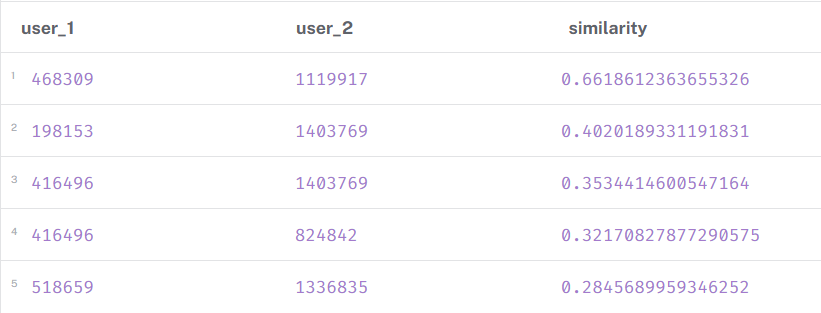

Berdasarkan hasil perhitungan Cosine Similarity pada representasi VSM User, diperoleh lima pasangan user dengan nilai similarity tertinggi. Pasangan user 468309 dan 1119917 memiliki nilai similarity tertinggi sebesar 0,661861, yang menunjukkan bahwa kedua user tersebut memiliki pola interaksi item yang relatif mirip berdasarkan representasi VSM yang digunakan.

Pasangan user 198153 dan 1403769 memiliki nilai similarity sebesar 0,402019, sedangkan pasangan user 416496 dan 1403769 memiliki nilai sebesar 0,353441. Dua pasangan lainnya masing-masing memiliki nilai similarity sebesar 0,321708 dan 0,284569.

Hasil ini menunjukkan bahwa tingkat kemiripan pola interaksi berbeda-beda pada setiap pasangan user. Semakin tinggi nilai cosine similarity, semakin mirip representasi pola interaksi kedua user. Perhitungan ini dilakukan pada sampel 100 user aktif yang dipilih dari representasi VSM User berdasarkan data training, sehingga hasilnya tidak mewakili seluruh pasangan user dalam dataset.

#### soal no.8  sebelum dan sesudah perhitungan similarity

In [ ]:
# sebelum perhitungan similarity
# MATCH (u:Visitor)-[r]->(i:Item)
# WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
# RETURN u, r, i
# LIMIT 50

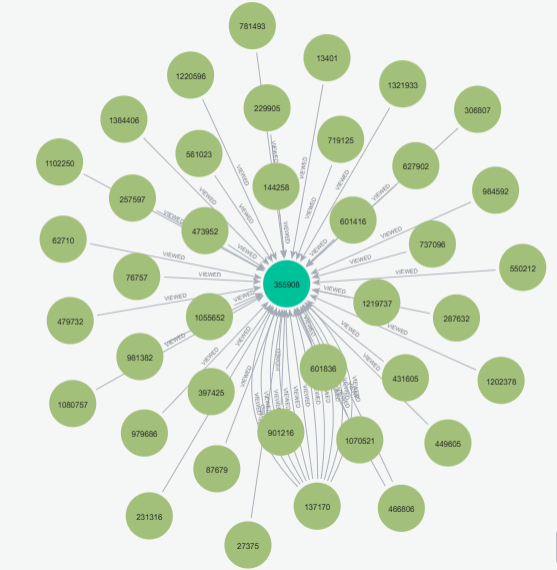

In [ ]:
# sesudah perhitungan similarity
# MATCH (u:Visitor)-[r]->(v:Visitor)
# WHERE type(r) = 'SIMILAR_TO'
# RETURN u, r, v
# ORDER BY r.similarity DESC
# LIMIT 5

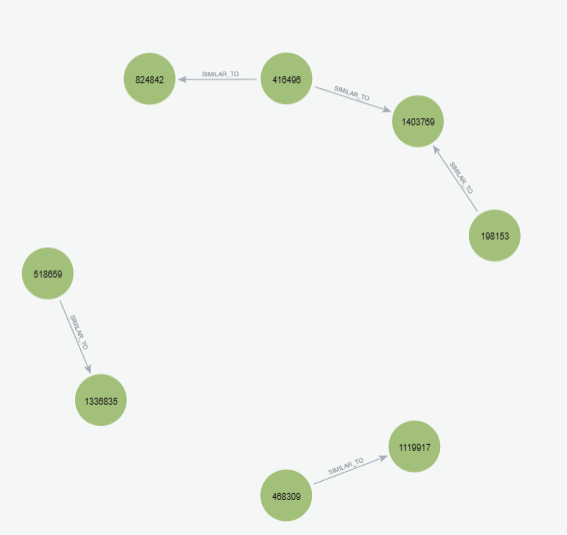

Sebelum Perhitungan Similarity graf awal memperlihatkan hubungan antara node Visitor dan Item berdasarkan aktivitas interaksi pengguna, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT. Setiap relasi menunjukkan jenis aktivitas yang dilakukan pengguna terhadap item. Visualisasi ini menggambarkan pola interaksi pengguna dengan item sebelum ditambahkan relasi kemiripan antaruser.

Setelah perhitungan Cosine Similarity dilakukan berdasarkan representasi VSM User, nilai similarity disimpan sebagai properti pada relasi SIMILAR_TO yang menghubungkan dua node Visitor. Relasi ini menunjukkan tingkat kemiripan pola interaksi antara sepasang pengguna berdasarkan representasi VSM yang digunakan. Graf hasil menampilkan lima pasangan user dengan nilai similarity tertinggi dari sampel 100 user aktif. 

Berdasarkan kedua visualisasi tersebut, dapat dilihat bahwa graf sebelum perhitungan similarity berfokus pada hubungan interaksi antara pengguna dan item, sedangkan graf setelah perhitungan similarity berfokus pada hubungan kemiripan antaruser. Dengan demikian, perhitungan similarity menghasilkan informasi tambahan mengenai pengguna yang memiliki pola interaksi item relatif serupa.

2.2 Analytics 

no. 1a

In [1]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

events_training = pd.read_csv("data/events_training.csv")
events_testing = pd.read_csv("data/events_testing.csv")

print("Data training:", events_training.shape)
print("Data testing:", events_testing.shape)

Data training: (1658879, 5)
Data testing: (1097222, 5)


In [14]:
item_per_user = (
    events_training.groupby("visitorid")["itemid"].nunique()
)

user_train_valid = item_per_user[item_per_user >= 2].index
user_test_valid = events_testing["visitorid"].unique()

user_eligible = np.intersect1d(
    user_train_valid,
    user_test_valid
)

if len(user_eligible) == 0:
    raise ValueError("Tidak ada user yang memenuhi kriteria.")

print("Jumlah user eligible:", len(user_eligible))

Jumlah user eligible: 13122


In [15]:
interaksi = events_training[
    ["visitorid", "itemid"]
].drop_duplicates()

user_ids = interaksi["visitorid"].unique()
item_ids = interaksi["itemid"].unique()

user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

baris = interaksi["visitorid"].map(user_to_idx).to_numpy()
kolom = interaksi["itemid"].map(item_to_idx).to_numpy()

X = csr_matrix(
    (
        np.ones(len(interaksi), dtype=np.float32),
        (baris, kolom)
    ),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
)

X_norm = normalize(X, norm="l2", axis=1)

print("Shape matriks user-item:", X.shape)
print("Jumlah interaksi unik:", X.nnz)

Shape matriks user-item: (842565, 189172)
Jumlah interaksi unik: 1284423


In [16]:
knn = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(X_norm)

,n_neighbors,6
,radius,1.0
,algorithm,'brute'
,leaf_size,30
,metric,'cosine'
,p,2
,metric_params,None
,n_jobs,-1


In [ ]:
rng = np.random.default_rng(42)
urutan_user = rng.permutation(user_eligible)

user_target = None
df_knn = None
skor_item = {}

for kandidat_user in urutan_user:

    if kandidat_user not in user_to_idx:
        continue

    idx_target = user_to_idx[kandidat_user]

    jarak, indeks = knn.kneighbors(
        X_norm[idx_target],
        n_neighbors=6
    )

    tetangga = []

    for dist, idx in zip(jarak[0], indeks[0]):
        if idx == idx_target:
            continue

        similarity = float(1 - dist)

        if similarity > 0:
            tetangga.append({
                "visitorid": int(user_ids[idx]),
                "similarity": similarity
            })

        if len(tetangga) == 5:
            break

    if len(tetangga) < 5:
        continue

    item_target = set(
        interaksi.loc[
            interaksi["visitorid"] == kandidat_user,
            "itemid"
        ]
    )

    skor_sementara = {}

    for row in tetangga:
        item_tetangga = interaksi.loc[
            interaksi["visitorid"] == row["visitorid"],
            "itemid"
        ]

        for item in item_tetangga:
            if item not in item_target:
                skor_sementara[item] = (
                    skor_sementara.get(item, 0.0)
                    + row["similarity"]
                )

    if len(skor_sementara) >= 3:
        user_target = int(kandidat_user)
        df_knn = pd.DataFrame(tetangga)
        skor_item = skor_sementara
        break

if user_target is None:
    raise ValueError(
        "Tidak ditemukan user dengan minimal 3 kandidat item baru."
    )

print("User target:", user_target)
print("Seed random: 42")
print("\nLima tetangga terdekat:")
display(df_knn)

User target: 1247122
Seed random: 42

Lima tetangga terdekat:


,visitorid,similarity
0,1243313,0.577350
1,621417,0.577350
2,688649,0.333333
3,1051017,0.288675
4,581604,0.258199


Pemilihan user dilakukan secara acak agar proses pemilihan dapat direproduksi. Data interaksi pada periode training kemudian digunakan untuk membentuk matriks user-item dengan ukuran 842.565 user dan 189.172 item, yang memuat 1.284.423 interaksi unik.

Selanjutnya, metode K-Nearest Neighbors (KNN) diterapkan dengan k=5 dan metrik cosine distance untuk mencari lima user yang memiliki pola interaksi paling mirip dengan user target. User target yang terpilih adalah 1247122.

Berdasarkan hasil tersebut, user 1243313 dan 621417 merupakan dua tetangga yang paling mirip dengan user target, dengan nilai cosine similarity sebesar 0.577350. Sementara itu, user 581604 memiliki nilai similarity paling rendah di antara lima tetangga tersebut, yaitu 0.258199. Kelima user ini selanjutnya digunakan sebagai dasar untuk menghasilkan rekomendasi item.  

no. 1b

In [ ]:
item_target = set(interaksi.loc[interaksi["visitorid"] == user_target,"itemid"])

skor_item = {}

for _, row in df_knn.iterrows():
    user_tetangga = row["visitorid"]
    similarity = row["similarity"]

    item_tetangga = interaksi.loc[
        interaksi["visitorid"] == user_tetangga,
        "itemid"
    ]

    for item in item_tetangga:
        if item not in item_target:
            skor_item[item] = (
                skor_item.get(item, 0.0) + similarity
            )
hasil_rekomendasi = pd.DataFrame(
    sorted(
        skor_item.items(),
        key=lambda x: (-x[1], x[0])
    )[:3],
    columns=["itemid", "skor_rekomendasi"]
)

print("User target:", user_target)
print("Jumlah kandidat item baru:", len(skor_item))
print("\nHasil rekomendasi:")
display(hasil_rekomendasi)

User target: 1247122
Jumlah kandidat item baru: 9

Hasil rekomendasi:


,itemid,skor_rekomendasi
0,307322,0.333333
1,442300,0.333333
2,246409,0.288675


Rekomendasi item dilakukan berdasarkan interaksi lima tetangga terdekat yang diperoleh pada bagian a. Item yang sudah pernah berinteraksi dengan user target pada data training tidak dimasukkan kembali ke dalam kandidat rekomendasi.

Setiap kandidat item diberikan skor berdasarkan penjumlahan nilai cosine similarity dari tetangga yang berinteraksi dengan item tersebut. Kandidat kemudian diurutkan berdasarkan skor tertinggi, dan tiga item teratas dipilih sebagai rekomendasi.

Berdasarkan hasil tersebut, item 307322 dan 442300 memperoleh skor rekomendasi tertinggi yang sama, yaitu 0.333333. Item 246409 berada pada peringkat ketiga dengan skor 0.288675. Ketiga item tersebut dipilih karena memiliki skor rekomendasi tertinggi di antara kandidat item baru yang tersedia.

Dengan demikian, sistem berhasil menghasilkan tiga rekomendasi item untuk user target 1247122 menggunakan pendekatan KNN dengan lima tetangga terdekat.

Soal no.2

2a

In [20]:
item_relevan = set(
    events_testing.loc[
        events_testing["visitorid"] == user_target,
        "itemid"
    ].unique()
)

print("User target:", user_target)
print("Item relevan pada data testing:", len(item_relevan))
print("Daftar item relevan:", sorted(item_relevan))

User target: 1247122
Item relevan pada data testing: 1
Daftar item relevan: [np.int64(230397)]


In [21]:
item_rekomendasi_5 = (
    hasil_rekomendasi.head(5)["itemid"].tolist()
)

hit5 = int(
    any(item in item_relevan for item in item_rekomendasi_5)
)

print("Item rekomendasi:", item_rekomendasi_5)
print("Hit@5:", hit5)

Item rekomendasi: [307322, 442300, 246409]
Hit@5: 0


Berdasarkan hasil perhitungan Hit@5, diperoleh nilai sebesar 0. Hal ini menunjukkan bahwa tidak ada item yang direkomendasikan dalam daftar rekomendasi teratas yang sesuai dengan item relevan pada data testing user target. User target yang digunakan adalah 1247122, dengan item relevan berupa 230397, sedangkan tiga item yang direkomendasikan adalah 307322, 442300, dan 246409. Karena tidak terdapat kecocokan antara item rekomendasi dan item relevan, nilai Hit@5 yang diperoleh adalah 0. Dengan demikian, sistem rekomendasi belum berhasil menemukan item yang benar-benar diinteraksikan oleh user target pada periode testing.

2b

In [23]:
item_rekomendasi_5 = (
    hasil_rekomendasi.head(5)["itemid"].tolist()
)

relevansi = [
    int(item in item_relevan)
    for item in item_rekomendasi_5
]

dcg = sum(
    rel / np.log2(pos + 2)
    for pos, rel in enumerate(relevansi)
)

jumlah_relevan = min(
    len(item_relevan),
    5,
    len(relevansi)
)

idcg = sum(
    1 / np.log2(pos + 2)
    for pos in range(jumlah_relevan)
)

ndcg = dcg / idcg if idcg > 0 else 0.0

print("User target:", user_target)
print("Item relevan:", sorted(item_relevan))
print("Item rekomendasi:", item_rekomendasi_5)
print("Relevansi:", relevansi)
print("DCG@5:", dcg)
print("IDCG@5:", idcg)
print("NDCG@5:", ndcg)


User target: 1247122
Item relevan: [np.int64(230397)]
Item rekomendasi: [307322, 442300, 246409]
Relevansi: [0, 0, 0]
DCG@5: 0.0
IDCG@5: 1.0
NDCG@5: 0.0


Berdasarkan hasil perhitungan NDCG@5, diperoleh nilai sebesar 0. Nilai ini menunjukkan bahwa tidak ada item rekomendasi yang sesuai dengan item relevan pada data testing user target, yaitu user 1247122 dengan item relevan 230397. Tiga item yang direkomendasikan adalah 307322, 442300, dan 246409, sehingga seluruh nilai relevansinya adalah 0. Evaluasi dilakukan berdasarkan tiga item rekomendasi yang tersedia, meskipun metrik yang digunakan adalah NDCG@5.

Berdasarkan hasil tersebut, nilai DCG@5 adalah 0, sedangkan IDCG@5 adalah 1. Karena tidak terdapat item relevan dalam daftar rekomendasi, nilai NDCG@5 yang diperoleh adalah 0. Dengan demikian, sistem rekomendasi belum berhasil merekomendasikan item yang relevan bagi user target pada periode testing.